#Dataset Description

The competition data comprises over fifty anonymized health characteristics linked to three age-related conditions. Your goal is to predict whether a subject has or has not been diagnosed with one of these conditions -- a binary classification problem.

Note that this is a Code Competition, in which the actual test set is hidden. In this version, we give some sample data in the correct format to help you author your solutions. When your submission is scored, this example test data will be replaced with the full test set. There are about 400 rows in the full test set.
Files and Field Descriptions

    **train.csv - The training set**.
        Id Unique identifier for each observation.
        AB-GL Fifty-six anonymized health characteristics. All are numeric except for EJ, which is categorical.
        Class A binary target: 1 indicates the subject has been diagnosed with one of the three conditions, 0 indicates they have not.
   ** test.csv** - The test set. Your goal is to predict the probability that a subject in this set belongs to each of the two classes.
    **greeks.csv** - Supplemental metadata, only available for the training set.
        Alpha Identifies the type of age-related condition, if present.
            A No age-related condition. Corresponds to class 0.
            B, D, G The three age-related conditions. Correspond to class 1.
        Beta, Gamma, Delta Three experimental characteristics.
        Epsilon The date the data for this subject was collected. Note that all of the data in the test set was collected after the training set was collected.
    **sample_submission.csv** - A sample submission file in the correct format. See the Evaluation page for more details.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
!unzip icr-identify-age-related-conditions.zip

Archive:  icr-identify-age-related-conditions.zip
  inflating: greeks.csv              
  inflating: sample_submission.csv   
  inflating: test.csv                
  inflating: train.csv               


In [3]:
greek = pd.read_csv('greeks.csv')
greek.head()

,Id,Alpha,Beta,Gamma,Delta,Epsilon
0,000ff2bfdfe9,B,C,G,D,3/19/2019
1,007255e47698,A,C,M,B,Unknown
2,013f2bd269f5,A,C,M,B,Unknown
3,043ac50845d5,A,C,M,B,Unknown
4,044fb8a146ec,D,B,F,B,3/25/2020


In [4]:
data = pd.read_csv('train.csv')
data.head(n=10)

,Id,AB,AF,AH,AM,AR,AX,AY,AZ,BC,...,FL,FR,FS,GB,GE,GF,GH,GI,GL,Class
0,000ff2bfdfe9,0.209377,3109.03329,85.200147,22.394407,8.138688,0.699861,0.025578,9.812214,5.555634,...,7.298162,1.73855,0.094822,11.339138,72.611063,2003.810319,22.136229,69.834944,0.120343,1
1,007255e47698,0.145282,978.76416,85.200147,36.968889,8.138688,3.632190,0.025578,13.517790,1.229900,...,0.173229,0.49706,0.568932,9.292698,72.611063,27981.562750,29.135430,32.131996,21.978000,0
2,013f2bd269f5,0.470030,2635.10654,85.200147,32.360553,8.138688,6.732840,0.025578,12.824570,1.229900,...,7.709560,0.97556,1.198821,37.077772,88.609437,13676.957810,28.022851,35.192676,0.196941,0
3,043ac50845d5,0.252107,3819.65177,120.201618,77.112203,8.138688,3.685344,0.025578,11.053708,1.229900,...,6.122162,0.49706,0.284466,18.529584,82.416803,2094.262452,39.948656,90.493248,0.155829,0
4,044fb8a146ec,0.380297,3733.04844,85.200147,14.103738,8.138688,3.942255,0.054810,3.396778,102.151980,...,8.153058,48.50134,0.121914,16.408728,146.109943,8524.370502,45.381316,36.262628,0.096614,1
5,04517a3c90bd,0.209377,2615.81430,85.200147,8.541526,8.138688,4.013127,0.025578,12.547282,1.229900,...,0.173229,0.49706,1.164956,21.915512,72.611063,24177.595550,28.525186,82.527764,21.978000,0
6,049232ca8356,0.348249,1733.65412,85.200147,8.377385,15.312480,1.913544,0.025578,6.547778,1.229900,...,4.408484,0.86130,0.467337,17.878444,192.453107,3332.467494,34.166222,100.086808,0.065096,0
7,057287f2da6d,0.269199,966.45483,85.200147,21.174189,8.138688,4.987617,0.025578,9.408886,1.229900,...,6.591896,0.49706,0.277693,18.445866,109.693986,21371.759850,35.208102,31.424696,0.092873,0
8,0594b00fb30a,0.346113,3238.43674,85.200147,28.888816,8.138688,4.021986,0.025578,8.243016,3.626448,...,4.762291,1.18262,0.067730,17.245908,147.218610,4589.611956,29.771721,54.675576,0.073416,0
9,05f2bc0155cd,0.324748,5188.68207,85.200147,12.968687,8.138688,4.593392,0.025578,10.685041,1.229900,...,0.173229,1.57151,0.318331,24.515421,98.929757,5563.130949,21.994831,33.300970,21.978000,0


In [5]:
data.columns.unique()

Index(['Id', 'AB', 'AF', 'AH', 'AM', 'AR', 'AX', 'AY', 'AZ', 'BC', 'BD ', 'BN',
       'BP', 'BQ', 'BR', 'BZ', 'CB', 'CC', 'CD ', 'CF', 'CH', 'CL', 'CR', 'CS',
       'CU', 'CW ', 'DA', 'DE', 'DF', 'DH', 'DI', 'DL', 'DN', 'DU', 'DV', 'DY',
       'EB', 'EE', 'EG', 'EH', 'EJ', 'EL', 'EP', 'EU', 'FC', 'FD ', 'FE', 'FI',
       'FL', 'FR', 'FS', 'GB', 'GE', 'GF', 'GH', 'GI', 'GL', 'Class'],
      dtype='object')

In [6]:
data['Class'].unique()

array([1, 0])

In [7]:
data.describe()

,AB,AF,AH,AM,AR,AX,AY,AZ,BC,BD,...,FL,FR,FS,GB,GE,GF,GH,GI,GL,Class
count,617.000000,617.000000,617.000000,617.000000,617.000000,617.000000,617.000000,617.000000,617.000000,617.000000,...,616.000000,617.000000,615.000000,617.000000,617.000000,617.000000,617.000000,617.000000,616.000000,617.000000
mean,0.477149,3502.013221,118.624513,38.968552,10.128242,5.545576,0.060320,10.566447,8.053012,5350.388655,...,5.433199,3.533905,0.421501,20.724856,131.714987,14679.595398,31.489716,50.584437,8.530961,0.175041
std,0.468388,2300.322717,127.838950,69.728226,10.518877,2.551696,0.416817,4.350645,65.166943,3021.326641,...,11.496257,50.181948,1.305365,9.991907,144.181524,19352.959387,9.864239,36.266251,10.327010,0.380310
min,0.081187,192.593280,85.200147,3.177522,8.138688,0.699861,0.025578,3.396778,1.229900,1693.624320,...,0.173229,0.497060,0.067730,4.102182,72.611063,13.038894,9.432735,0.897628,0.001129,0.000000
25%,0.252107,2197.345480,85.200147,12.270314,8.138688,4.128294,0.025578,8.129580,1.229900,4155.702870,...,0.173229,0.497060,0.067730,14.036718,72.611063,2798.992584,25.034888,23.011684,0.124392,0.000000
50%,0.354659,3120.318960,85.200147,20.533110,8.138688,5.031912,0.025578,10.461320,1.229900,4997.960730,...,3.028141,1.131000,0.250601,18.771436,72.611063,7838.273610,30.608946,41.007968,0.337827,0.000000
75%,0.559763,4361.637390,113.739540,39.139886,8.138688,6.431634,0.036845,12.969516,5.081244,6035.885700,...,6.238814,1.512060,0.535067,25.608406,127.591671,19035.709240,36.863947,67.931664,21.978000,0.000000
max,6.161666,28688.187660,1910.123198,630.518230,178.943634,38.270880,10.315851,38.971568,1463.693448,53060.599240,...,137.932739,1244.227020,31.365763,135.781294,1497.351958,143790.071200,81.210825,191.194764,21.978000,1.000000


In [8]:
data.dtypes

,0
Id,object
AB,float64
AF,float64
AH,float64
AM,float64
AR,float64
AX,float64
AY,float64
AZ,float64
BC,float64


In [9]:
data['EJ'].unique()

array(['B', 'A'], dtype=object)

In [10]:
data['EJ'] = data['EJ'].map({'A':0,'B':1})

In [11]:
data['EJ']

,EJ
0,1
1,0
2,1
3,1
4,1
...,...
612,0
613,1
614,0
615,1


In [12]:
data.dtypes

,0
Id,object
AB,float64
AF,float64
AH,float64
AM,float64
AR,float64
AX,float64
AY,float64
AZ,float64
BC,float64


In [13]:
data = data.drop(['Id'],axis=1)


In [14]:
data = data.dropna()

In [15]:
X_train,X_test,y_train,y_test = train_test_split(data.drop(['Class'],axis=1),data['Class'],test_size=0.3)

In [16]:
y_train.unique(),X_train

(array([0, 1]),
            AB          AF          AH         AM         AR        AX  \
 20   0.555490  6232.74146   85.200147  25.739167   8.138688  4.996476   
 555  0.282018  4088.00436   85.200147  15.763730   8.138688  4.119435   
 294  0.542671  3203.77508   85.200147  33.363981   8.138688  5.935530   
 254  0.183739  2315.68106   98.019795  12.031845   8.138688  6.936597   
 212  0.393116  2304.47404   85.200147  23.286343  12.957924  6.777135   
 ..        ...         ...         ...        ...        ...       ...   
 240  0.470030  7549.83009  102.583311  35.296509  13.775988  5.421708   
 79   0.572582  4889.85805   98.106885  15.822573   8.138688  4.930034   
 323  0.209377  6440.59284   86.349735  12.620275   8.138688  3.224676   
 220  0.354659  2587.64913   85.200147  16.231377  12.506940  5.448285   
 49   0.478576  5192.25520  194.576478  13.230384   8.138688  7.290957   
 
            AY         AZ         BC          BD   ...         FI         FL  \
 20   0.025578

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

<Axes: >

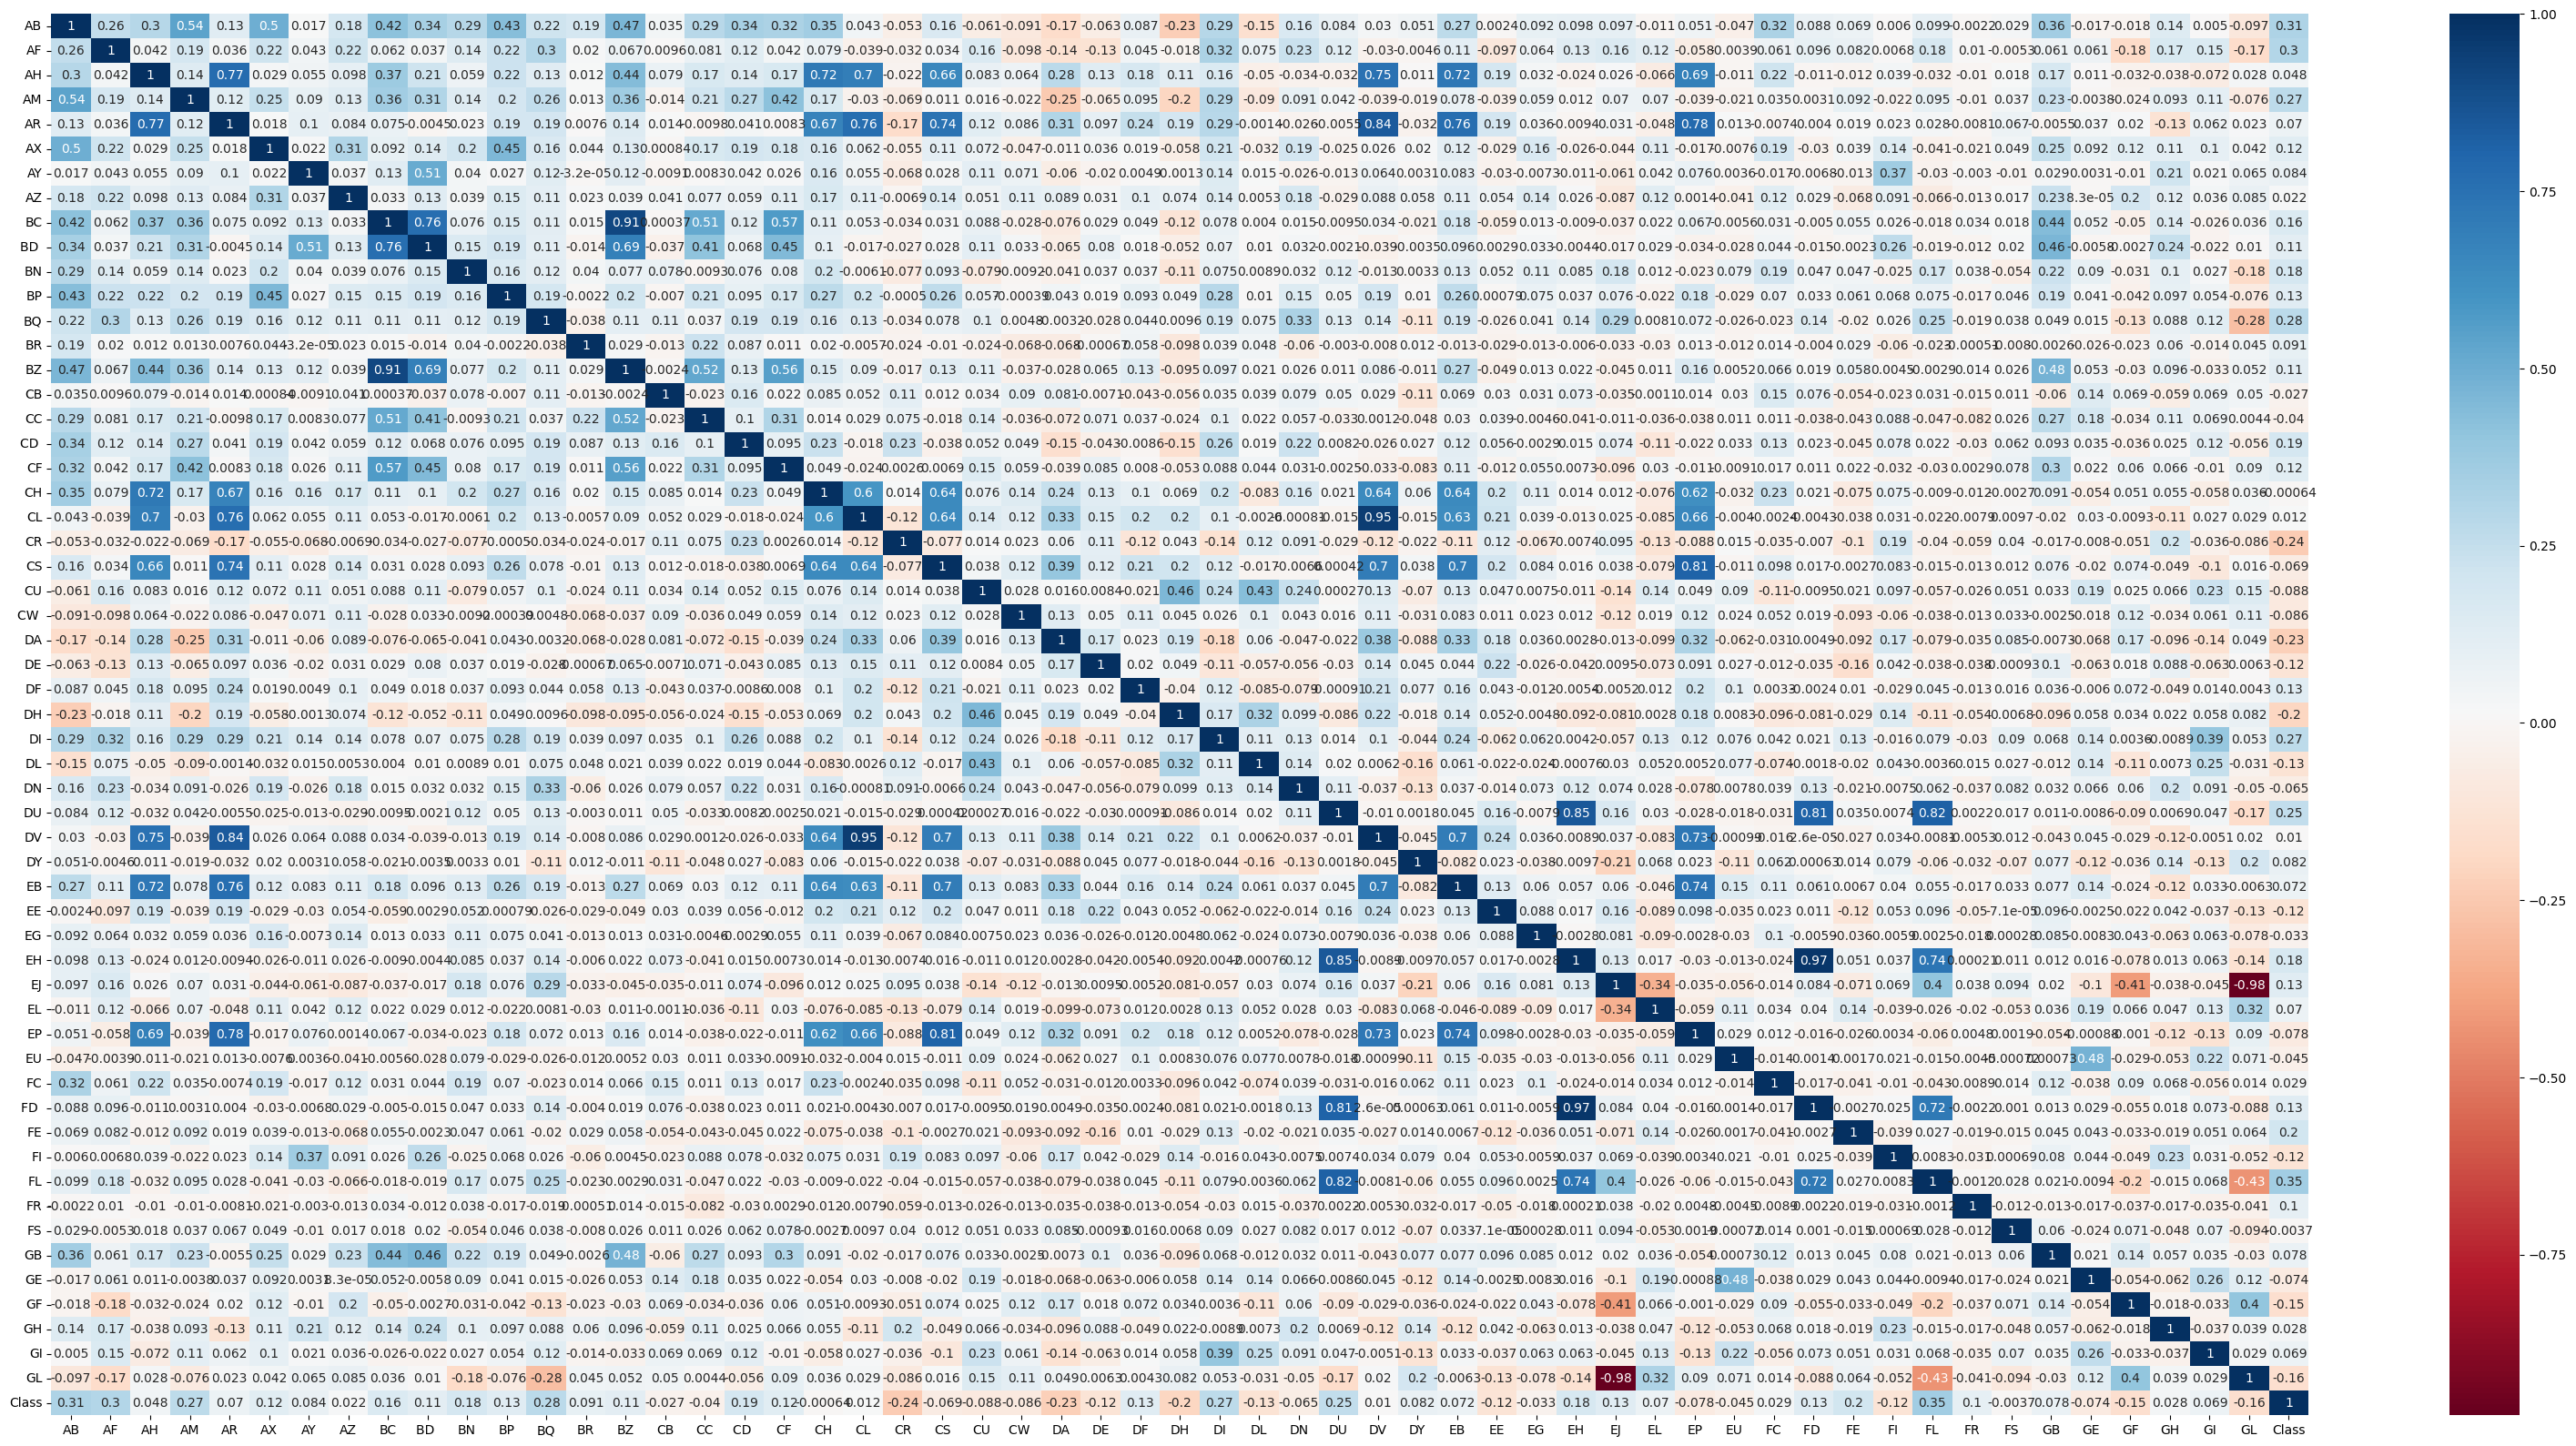

In [18]:
plt.figure(figsize=(40,20))
sns.heatmap(data.corr(),annot=True,cmap='RdBu')

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
model = LogisticRegression(solver='saga',max_iter=1000)

In [20]:
model.fit(X_train,y_train)

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LogisticRegression(max_iter=1000, solver='saga')

In [21]:
X_train.dtypes

,0
AB,float64
AF,float64
AH,float64
AM,float64
AR,float64
AX,float64
AY,float64
AZ,float64
BC,float64
BD,float64


In [22]:
pred = model.predict(X_test)
accuracy_score(y_test,pred)

0.8181818181818182

In [23]:
from sklearn.metrics import confusion_matrix
from sklearn import metrics
confusion_matrix(y_test,pred)

array([[132,   2],
       [ 28,   3]])

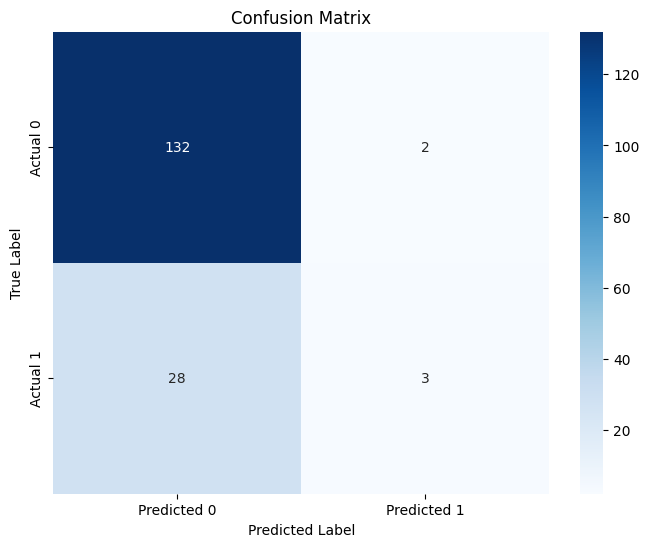

In [24]:
# prompt: confusion matrix that are visual

cm = confusion_matrix(y_test, pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [25]:
## Knn model from scratch
import numpy
from collections import Counter

def euclidean_distance(x1, x2):
    distance = np.sqrt(np.sum((x1-x2)**2))
    return distance

class KNN:
    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        self.X_train = X
        self.y_train = np.array(y)

    def predict(self, X):
        predictions = [self._predict(x) for x in X]
        return predictions

    def _predict(self, x):
        # compute the distance
        distances = [euclidean_distance(x, x_train) for x_train in self.X_train]

        # get the closest k
        k_indices = np.argsort(distances)[:self.k]
        k_nearest_labels = [self.y_train[i] for i in k_indices]

        # majority voye
        most_common = Counter(k_nearest_labels).most_common()
        return most_common[0][0]



In [26]:
model = KNN()
model.fit(X_train_scaled,y_train)

In [27]:
pred = model.predict(X_test_scaled)

In [28]:
score = accuracy_score(y_test,pred)

In [29]:
cm_knn = confusion_matrix(y_test, pred)

<Axes: >

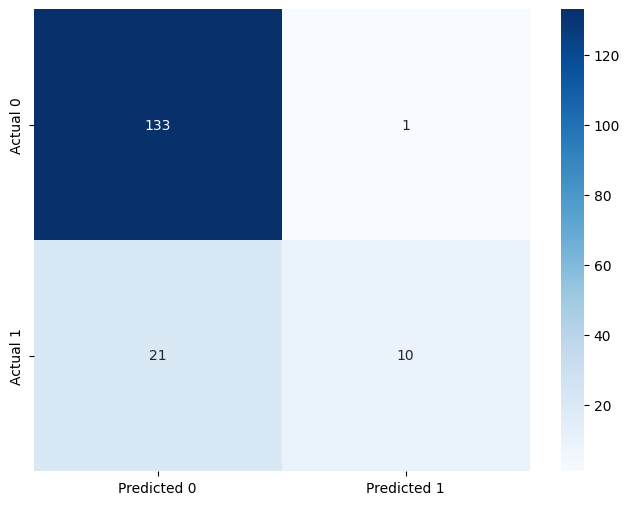

In [30]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])

<Axes: >

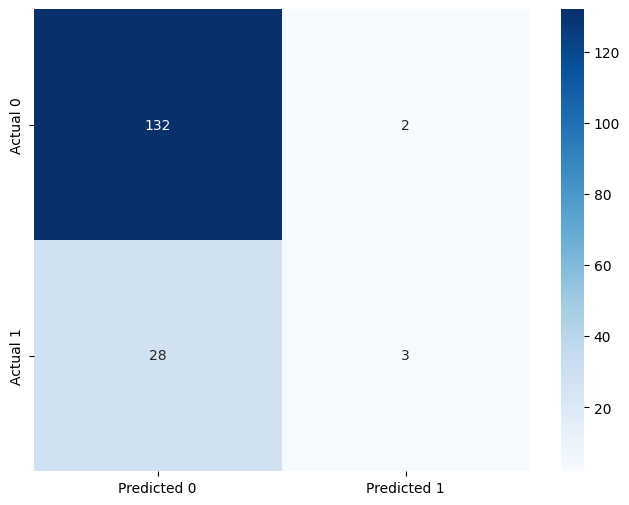

In [31]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])

In [32]:
import numpy as np
from collections import Counter

def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2) ** 2))

class KNN:
    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        self.X_train = np.array(X)
        self.y_train = np.array(y)

    def predict(self, X, weighted=False):
        predictions = [self._predict(x, weighted) for x in X]
        return predictions

    def _predict(self, x, weighted):
        # Calculate the distances
        distances = [euclidean_distance(x, x_train) for x_train in self.X_train]

        k_indices = np.argsort(distances)[:self.k]
        k_nearest_labels = [self.y_train[i] for i in k_indices]
        k_nearest_distances = [distances[i] for i in k_indices]

        if not weighted:
            most_common = Counter(k_nearest_labels).most_common()
            return most_common[0][0]
        else:
            # Weighted vote
            weights = [1 / (dist + 1e-9) for dist in k_nearest_distances]
            weighted_votes = {}

            for label, weight in zip(k_nearest_labels, weights):
                if label not in weighted_votes:
                    weighted_votes[label] = 0
                weighted_votes[label] += weight

            return max(weighted_votes, key=weighted_votes.get)


In [33]:
X_train = np.array(X_train, dtype=float)
X_test = np.array(X_test, dtype=float)

In [34]:
dic_majority ={}
dic_weight = {}
for i in range(1, 12):
    knn = KNN(k=i)
    knn.fit(X_train, y_train)

    predictions_majority = knn.predict(X_test, weighted=False)
    print(f"Predictions (Majority Voting) for k={i}:", predictions_majority)
    acc_majority = accuracy_score(y_test, predictions_majority)
    print(f"Accuracy (Majority Voting) for k={i}:", acc_majority)
    dic_majority[i] = acc_majority

    predictions_weighted = knn.predict(X_test, weighted=True)
    print(f"Predictions (Weighted Voting) for k={i}:", predictions_weighted)
    acc_weighted = accuracy_score(y_test, predictions_weighted)
    print(f"Accuracy (Weighted Voting) for k={i}:", acc_weighted)
    dic_weight[i] = acc_weighted

Predictions (Majority Voting) for k=1: [0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0]
Accuracy (Majority Voting) for k=1: 0.7333333333333333
Predictions (Weighted Voting) for k=1: [0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0

In [35]:
print(max(dic_majority.values()))
print(max(dic_weight.values()))

0.8363636363636363
0.8484848484848485


In [36]:
knn = KNN(k=11)
knn.fit(X_train, y_train)

predictions_majority = knn.predict(X_test, weighted=False)
print("Predictions (Majority Voting):", predictions_majority)

predictions_weighted = knn.predict(X_test, weighted=True)
print("Predictions (Weighted Voting):", predictions_weighted)

Predictions (Majority Voting): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Predictions (Weighted Voting): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

In [37]:
print("X_train dtype:", np.array(X_train).dtype)
print("X_test dtype:", np.array(X_test).dtype)


X_train dtype: float64
X_test dtype: float64


In [38]:
cm_weight = confusion_matrix(y_test, predictions_weighted)
cm_no_weight = confusion_matrix(y_test, predictions_majority)

In [42]:
accuracy_score(y_test,predictions_weighted),accuracy_score(y_test,predictions_majority)

(0.8484848484848485, 0.8303030303030303)

In [39]:
cm_weight,cm_no_weight

(array([[133,   1],
        [ 24,   7]]),
 array([[134,   0],
        [ 28,   3]]))

<Axes: >

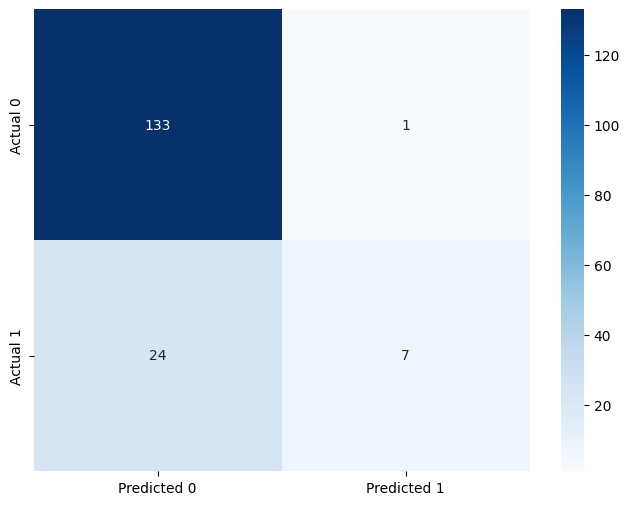

In [40]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm_weight, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])

<Axes: >

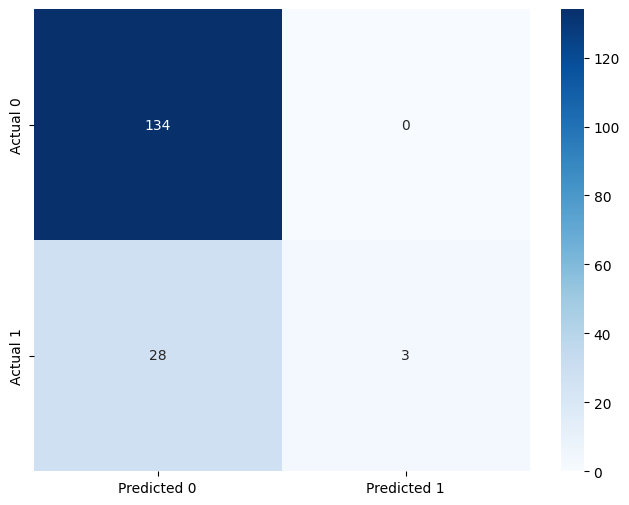

In [41]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm_no_weight, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])